# 11 — Myeloid abundance by condition × site, one point per mouse

`rtAdvantage/02b` reported that **the CAR target explains 51.0% of the CLR variance in
`M1_like_Mac`** (vs 3.6% for RT). That is an ANOVA percentage, and an ANOVA percentage cannot
answer the three questions that decide what it means:

1. **Direction** — is PSCA *expanding* M1, or is TAG72 *losing* it? A variance term is
   sign-free and says neither.
2. **Leverage** — with n = 3 mice per arm, one animal can carry a 51%.
3. **Consistency** — does the gap exist in **both** the RT and non-RT strata, or is it one of
   them averaged with nothing?

This notebook is the plot that answers them: every sample as a point, every mouse's two tumours
joined, nothing hidden behind a mean.

### The metric, and why two of them
- **% of the macrophage compartment** (primary). M1/M2/Intermediate/SPP1-TAM as a share of
  macrophages. This is what "the M1/M2 balance shifted" actually means, and — being a ratio
  *within* one compartment — it is robust to the dissociation capture bias that makes raw
  single-cell fractions unreliable.
- **% of all cells** (secondary). The literal reading of "abundance", and the metric closest to
  the CLR that 02b decomposed. It **is** capture-bias affected, and `NoTx` is 25–42% tumour vs
  4–6% in treated arms, so cross-arm comparisons on this metric are distorted by construction.

Where the two disagree, the compartment share is the one to trust, and the disagreement is itself
the finding.

> **`NoTx` is the only untreated reference available, and it is a compromised one.** Direction
> ("expansion" vs "loss") is only definable against a baseline, so it is shown — but its tumour
> content is wildly different from the treated arms, so it is drawn in grey and set apart, and
> any directional claim is stated as *relative to NoTx, on compartment share*, never as absolute.

## 1. Config and data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
from scipy import stats

_HPC, _LOC = Path("/coh_labs/yunroseli/Jona/CAR-T"), Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _HPC if _HPC.exists() else _LOC
OUT  = PROJ/"results/spp1_analysis/sc_spp1tam_conditions"
FIG  = OUT/"figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40)

# Rebuild per-cell labels from the single-cell object (or reuse a cached frame if present).
CACHE = Path("/private/tmp/claude-502/-Users-janzules-Roselab-Spatial-CAR-T-code/"
             "e581d415-7df3-4854-a3bf-2ca0c390bac9/scratchpad/rt/cell_scores.parquet")
if CACHE.exists():
    cells = pd.read_parquet(CACHE)[["sample","cond","tu","mouse","ct","is_mac","TAM_global"]]
    print(f"loaded cached per-cell labels: {len(cells):,} cells")
else:
    import scanpy as sc, anndata as ad, h5py
    SC_REF = (PROJ/"data/zarr/fullDataset/annotating_references/annotation_v4.h5ad" if PROJ is _HPC
              else PROJ/"data/sc-reference/annotation_v4.h5ad")
    with h5py.File(SC_REF,"r") as f:
        obs=ad.io.read_elem(f["obs"]); var=ad.io.read_elem(f["var"]); X=ad.io.read_elem(f["X"])
    adata=ad.AnnData(X=X,obs=obs,var=var); del X
    MACL=["M1_like_Mac","M2_like_Mac","Intermediate_Mac"]
    o=adata.obs
    o["cond"]=o["condition"].astype(str); o["sample"]=o["file_name"].astype(str)
    o["tu"]=o["sample"].str.extract(r"_(Tu\d)_")[0].values
    o["mouse"]=o["sample"].str.replace(r"_Tu\d_","_",regex=True)
    o["ct"]=o["cell_type_lvl2"].astype(str); o["is_mac"]=o["ct"].isin(MACL)
    sig=[g for g in pd.read_csv(PROJ/"results/spp1_analysis/sc_spp1_tam_signature.csv")["gene"]
         if g in adata.var_names]
    sc.tl.score_genes(adata, sig, score_name="S", ctrl_size=50, random_state=0)
    m,s=o["is_mac"].values, adata.obs["S"].values
    o["TAM_global"]=m & (s>=np.quantile(s[m],0.75))
    cells=o[["sample","cond","tu","mouse","ct","is_mac","TAM_global"]].copy()
    print(f"rebuilt per-cell labels: {len(cells):,} cells")

POPS  = ["M1_like_Mac","M2_like_Mac","Intermediate_Mac","SPP1_TAM"]
NICE  = {"M1_like_Mac":"M1-like Mac","M2_like_Mac":"M2-like Mac",
         "Intermediate_Mac":"Intermediate Mac","SPP1_TAM":"SPP1-TAM"}
ARMS  = ["NoTx","CyPSCA","RTCyPSCA","CyTAG72","RTCyTAG72"]
GROUPS= [f"{a}_{t}" for a in ARMS for t in ["Tu1","Tu2"]]
CART  = {"NoTx":"none","CyPSCA":"PSCA","RTCyPSCA":"PSCA","CyTAG72":"TAG72","RTCyTAG72":"TAG72"}
print("\nmice per arm x site:")
print(cells.groupby(["cond","tu"], observed=True)["mouse"].nunique().unstack().to_string())

loaded cached per-cell labels: 93,548 cells

mice per arm x site:
tu         Tu1  Tu2
cond               
CyPSCA       3    3
CyTAG72      2    3
NoTx         3    3
RTCyPSCA     3    3
RTCyTAG72    3    3


## 2. Per-sample abundance table

One row per sample. `pct_mac` is the share of the macrophage compartment; `pct_cells` the share
of all cells. SPP1-TAM is the signature top-quartile call, which is defined *within* macrophages,
so its `pct_mac` is the natural metric and its `pct_cells` is shown only for parity.

In [2]:
rows=[]
for smp, d in cells.groupby("sample", observed=True):
    n_all, n_mac = len(d), int(d.is_mac.sum())
    r = dict(sample=smp, cond=d.cond.iloc[0], tu=d.tu.iloc[0], mouse=d.mouse.iloc[0],
             n_cells=n_all, n_mac=n_mac)
    for p in POPS:
        k = int(d.TAM_global.sum()) if p=="SPP1_TAM" else int((d.ct==p).sum())
        r[f"{p}__n"]         = k
        r[f"{p}__pct_mac"]   = 100*k/n_mac if n_mac else np.nan
        r[f"{p}__pct_cells"] = 100*k/n_all
    rows.append(r)
A = pd.DataFrame(rows)
A["group"] = A.cond + "_" + A.tu
A["cart"]  = A.cond.map(CART)
A["RT"]    = A.cond.str.startswith("RT")
A = A.sort_values(["cond","tu","mouse"]).reset_index(drop=True)
A.to_csv(OUT/"myeloid_abundance_per_sample.csv", index=False)

print("=== per-sample table (% of macrophage compartment) ===")
print(A[["sample","cond","tu","n_cells","n_mac"]+[f"{p}__pct_mac" for p in POPS]]
        .to_string(index=False, float_format=lambda x: f"{x:.1f}"))

=== per-sample table (% of macrophage compartment) ===
         sample      cond  tu  n_cells  n_mac  M1_like_Mac__pct_mac  M2_like_Mac__pct_mac  Intermediate_Mac__pct_mac  SPP1_TAM__pct_mac
   CyPSCA_Tu1_1    CyPSCA Tu1     3827   1983                  42.8                  39.1                       18.1               24.3
   CyPSCA_Tu1_2    CyPSCA Tu1     4322   2073                  41.1                  39.3                       19.7               18.0
   CyPSCA_Tu1_3    CyPSCA Tu1     1836    714                  48.0                  39.1                       12.9               16.2
   CyPSCA_Tu2_1    CyPSCA Tu2     3835   1873                  57.1                  25.4                       17.5               10.9
   CyPSCA_Tu2_2    CyPSCA Tu2     1308    661                  38.9                  42.8                       18.3               21.5
   CyPSCA_Tu2_3    CyPSCA Tu2      483    254                  56.3                  26.4                       17.3             

## 3. The figure

Small multiples, one panel per population. Every point is one sample; the thin line joins the two
tumours of one mouse (Tu1 irradiated → Tu2 abscopal). Colour is the CAR background — three
categories, so it is within the all-pairs-validated first three slots of the categorical palette.
Group means are the short black bars. `NoTx` is grey and separated by a rule, because it is a
compromised reference (see the header).

Identity is never colour-alone: each group is directly labelled on the x-axis, the legend is
present, and §2's table is the table view (the aqua slot sits under 3:1 contrast on a light
surface, which obliges exactly that relief).

saved -> /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis/sc_spp1tam_conditions/figures/11_myeloid_abundance_pct_mac.png


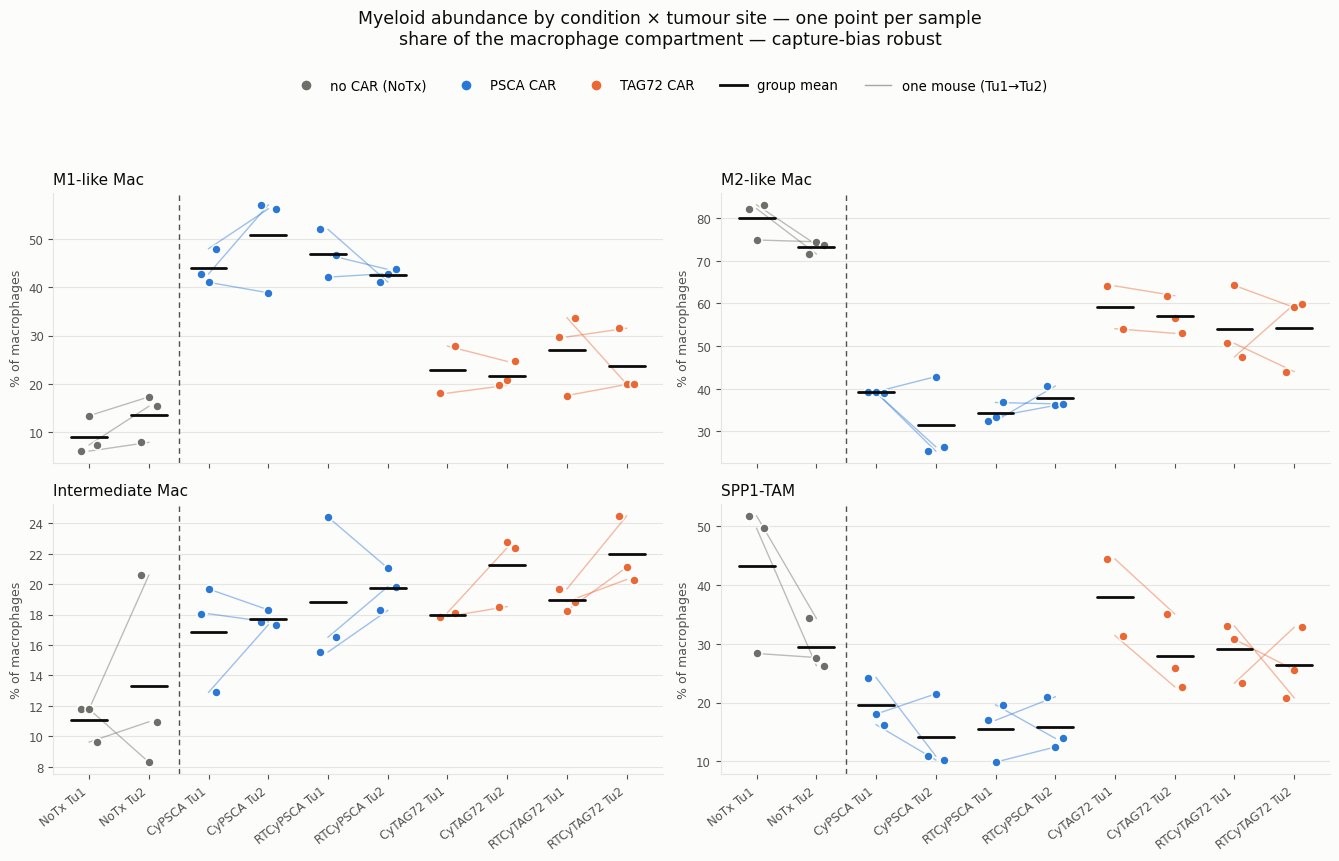

saved -> /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis/sc_spp1tam_conditions/figures/11_myeloid_abundance_pct_cells.png


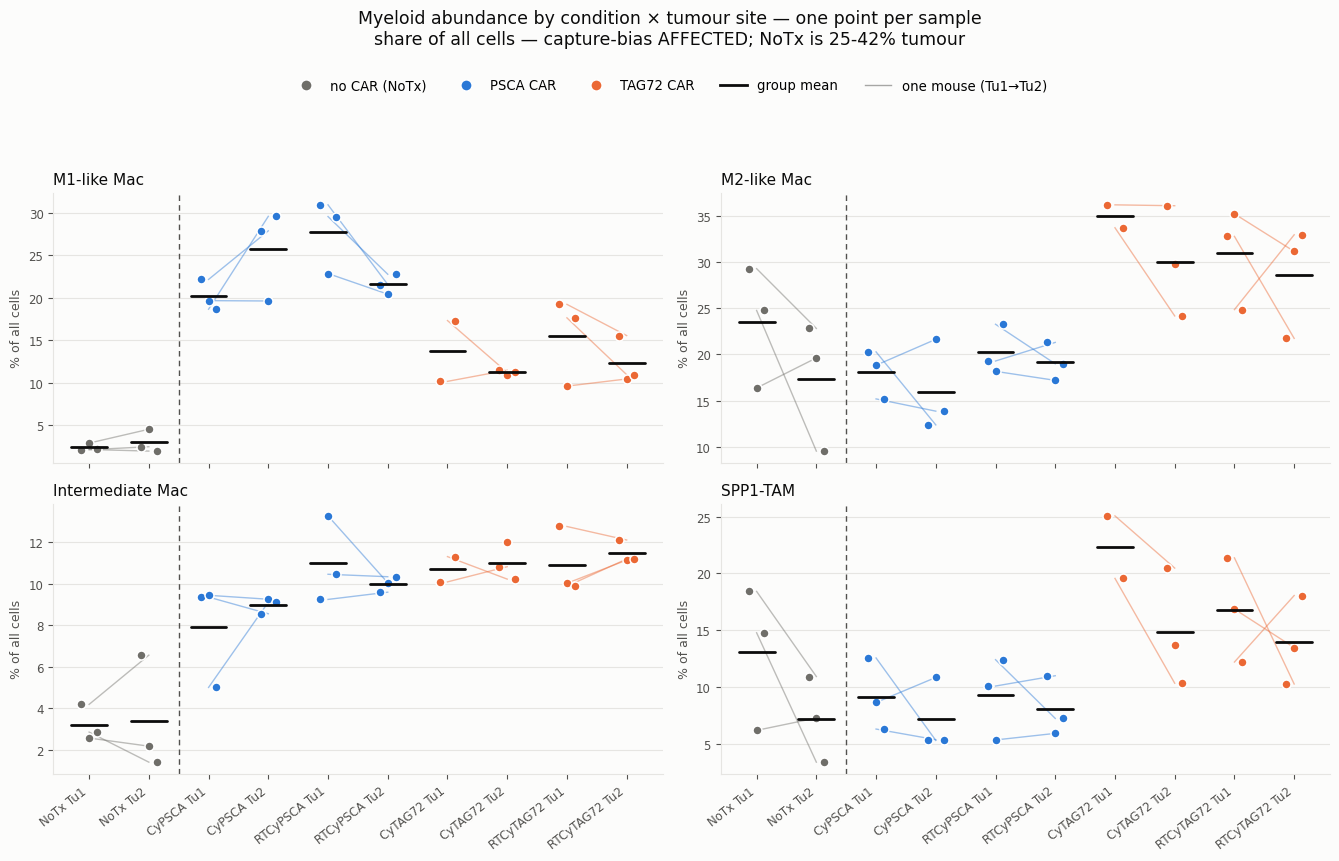

In [3]:
SER    = {"none":"#6f6e69", "PSCA":"#2a78d6", "TAG72":"#eb6834"}   # slots 1,2 + neutral for NoTx
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e2", "#fcfcfb"

def panel(ax, metric, pop, show_xlab):
    xs = {g:i for i,g in enumerate(GROUPS)}
    col = f"{pop}__{metric}"
    for mouse, d in A.groupby("mouse", observed=True):          # paired Tu1->Tu2 line
        d = d.sort_values("tu")
        if len(d)==2:
            ax.plot([xs[d.group.iloc[0]], xs[d.group.iloc[1]]], d[col].values,
                    color=SER[d.cart.iloc[0]], lw=1.0, alpha=.45, zorder=2)
    for g in GROUPS:
        d = A[A.group==g]
        if not len(d): continue
        x = xs[g]
        jit = np.linspace(-.13,.13,len(d)) if len(d)>1 else np.array([0.])
        ax.scatter(x+jit, d[col], s=42, color=SER[d.cart.iloc[0]],
                   edgecolor="white", linewidth=1.1, zorder=3)
        ax.plot([x-.30,x+.30],[d[col].mean()]*2, color=INK, lw=2.0, solid_capstyle="round", zorder=4)
    ax.axvline(1.5, color=MUTED, lw=1.0, ls=(0,(4,3)), zorder=1)   # NoTx separator
    ax.set_xlim(-.6, len(GROUPS)-.4)
    ax.set_xticks(range(len(GROUPS)))
    ax.set_xticklabels([g.replace("_Tu"," Tu") for g in GROUPS] if show_xlab else [],
                       rotation=38, ha="right", fontsize=8.5, color=INK)
    ax.set_ylabel("% of macrophages" if metric=="pct_mac" else "% of all cells",
                  fontsize=9, color=MUTED)
    ax.set_title(NICE[pop], fontsize=11, color=INK, loc="left", pad=6)
    ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
    for sp in ["top","right"]: ax.spines[sp].set_visible(False)
    for sp in ["left","bottom"]: ax.spines[sp].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8.5)

for metric, fname, sub in [("pct_mac","11_myeloid_abundance_pct_mac",
                            "share of the macrophage compartment — capture-bias robust"),
                           ("pct_cells","11_myeloid_abundance_pct_cells",
                            "share of all cells — capture-bias AFFECTED; NoTx is 25-42% tumour")]:
    fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.2), facecolor=SURF)
    for ax,(i,pop) in zip(axes.ravel(), enumerate(POPS)):
        ax.set_facecolor(SURF); panel(ax, metric, pop, show_xlab=(i>=2))
    handles=[Line2D([],[],marker="o",ls="",ms=8,mfc=SER[k],mec="white",label=lab)
             for k,lab in [("none","no CAR (NoTx)"),("PSCA","PSCA CAR"),("TAG72","TAG72 CAR")]]
    handles.append(Line2D([],[],color=INK,lw=2,label="group mean"))
    handles.append(Line2D([],[],color=MUTED,lw=1,alpha=.5,label="one mouse (Tu1→Tu2)"))
    fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False,
               bbox_to_anchor=(.5,.975), fontsize=9.5)
    fig.suptitle(f"Myeloid abundance by condition × tumour site — one point per sample\n{sub}",
                 fontsize=12.5, color=INK, y=1.045, x=.5)
    fig.tight_layout(rect=[0,0,1,.93])
    for ext in ["png","pdf"]:
        fig.savefig(FIG/f"{fname}.{ext}", dpi=240, bbox_inches="tight", facecolor=SURF)
    print(f"saved -> {FIG/fname}.png")
    plt.show()

## 4. Question 1 — expansion or loss? (direction, against NoTx)

Direction only exists relative to a baseline. On **compartment share**, which is the metric that
survives the NoTx tumour-content problem.

In [4]:
for metric in ["pct_mac","pct_cells"]:
    print(f"\n=== group means, {metric} ===")
    g = A.groupby("group", observed=True)[[f"{p}__{metric}" for p in POPS]].mean().reindex(GROUPS)
    g.columns=[NICE[p] for p in POPS]
    print(g.round(1).to_string())

print("\n=== M1-like: each CAR arm vs NoTx, same site (compartment share) ===")
base = A[A.cond=="NoTx"].groupby("tu")["M1_like_Mac__pct_mac"].mean()
rows=[]
for arm in ["CyPSCA","RTCyPSCA","CyTAG72","RTCyTAG72"]:
    for site in ["Tu1","Tu2"]:
        v = A[(A.cond==arm)&(A.tu==site)]["M1_like_Mac__pct_mac"]
        rows.append(dict(arm=arm, site=site, mean=v.mean(), NoTx=base[site],
                         delta_vs_NoTx=v.mean()-base[site],
                         fold=v.mean()/base[site], n=len(v)))
D = pd.DataFrame(rows)
print(D.to_string(index=False, float_format=lambda x: f"{x:+.2f}"))
print(f"""
  READ: if PSCA arms sit ABOVE NoTx and TAG72 arms sit AT NoTx -> PSCA EXPANDS M1.
        If PSCA sits AT NoTx and TAG72 BELOW -> TAG72 DEPLETES M1.
        If both move -> both, and the 51% is the gap between two real shifts.""")


=== group means, pct_mac ===
               M1-like Mac  M2-like Mac  Intermediate Mac  SPP1-TAM
group                                                              
NoTx_Tu1               8.9         80.0              11.1      43.2
NoTx_Tu2              13.5         73.2              13.3      29.4
CyPSCA_Tu1            44.0         39.2              16.9      19.5
CyPSCA_Tu2            50.8         31.5              17.7      14.2
RTCyPSCA_Tu1          47.0         34.2              18.8      15.5
RTCyPSCA_Tu2          42.6         37.7              19.7      15.8
CyTAG72_Tu1           22.9         59.1              18.0      37.9
CyTAG72_Tu2           21.7         57.1              21.2      27.9
RTCyTAG72_Tu1         27.0         54.1              18.9      29.0
RTCyTAG72_Tu2         23.8         54.3              22.0      26.4

=== group means, pct_cells ===
               M1-like Mac  M2-like Mac  Intermediate Mac  SPP1-TAM
group                                                 

## 5. Question 2 — does one mouse drive it? (leverage)

The PSCA-minus-TAG72 gap in M1-like compartment share, recomputed with each mouse removed in
turn. If the gap survives every deletion, no single animal carries it.

In [5]:
def m1_gap(df, stratum=None):
    d = df[df.cart.isin(["PSCA","TAG72"])]
    if stratum=="RT":    d = d[d.RT]
    if stratum=="nonRT": d = d[~d.RT]
    a = d[d.cart=="PSCA"]["M1_like_Mac__pct_mac"]; b = d[d.cart=="TAG72"]["M1_like_Mac__pct_mac"]
    return a.mean()-b.mean(), len(a), len(b)

full,_,_ = m1_gap(A)
print(f"full-data PSCA - TAG72 gap in M1-like (% of macrophages): {full:+.2f} pp\n")
loo=[]
for mouse in sorted(A[A.cart.isin(['PSCA','TAG72'])].mouse.unique()):
    g,_,_ = m1_gap(A[A.mouse!=mouse])
    loo.append(dict(dropped=mouse, gap=g, change=g-full))
L = pd.DataFrame(loo).sort_values("gap")
print(L.to_string(index=False, float_format=lambda x: f"{x:+.2f}"))
print(f"\n  gap range across all leave-one-mouse-out refits: {L.gap.min():+.2f} to {L.gap.max():+.2f} pp")
print(f"  sign flips in any refit: {'YES' if (np.sign(L.gap)!=np.sign(full)).any() else 'NO'}")
print(f"  largest single-mouse influence: {L.iloc[(L.change.abs()).argmax()].dropped} "
      f"({L.change.abs().max():+.2f} pp)")

print("\n=== is it separated? every PSCA sample vs every TAG72 sample ===")
a = A[A.cart=="PSCA"]["M1_like_Mac__pct_mac"]; b = A[A.cart=="TAG72"]["M1_like_Mac__pct_mac"]
print(f"  PSCA  range {a.min():.1f}-{a.max():.1f} (n={len(a)}), median {a.median():.1f}")
print(f"  TAG72 range {b.min():.1f}-{b.max():.1f} (n={len(b)}), median {b.median():.1f}")
print(f"  fully separated: {'YES' if a.min()>b.max() or b.min()>a.max() else 'NO (ranges overlap)'}")
print(f"  Mann-Whitney p = {stats.mannwhitneyu(a,b).pvalue:.4f}  (samples, not mice — "
      f"pseudoreplicated; mouse-level below)")
am = A[A.cart=="PSCA"].groupby("mouse")["M1_like_Mac__pct_mac"].mean()
bm = A[A.cart=="TAG72"].groupby("mouse")["M1_like_Mac__pct_mac"].mean()
print(f"  mouse level: PSCA n={len(am)} mean {am.mean():.1f} | TAG72 n={len(bm)} mean {bm.mean():.1f}"
      f" | MWU p = {stats.mannwhitneyu(am,bm).pvalue:.4f}  (floor is 1/C(12,6)-ish at this n)")

full-data PSCA - TAG72 gap in M1-like (% of macrophages): +22.13 pp

    dropped    gap  change
   CyPSCA_3 +20.91   -1.22
RTCyTAG72_2 +20.97   -1.16
  CyTAG72_1 +21.01   -1.12
   CyPSCA_1 +21.35   -0.78
  CyTAG72_2 +21.82   -0.31
 RTCyPSCA_1 +22.03   -0.10
 RTCyPSCA_3 +22.30   +0.17
  CyTAG72_3 +22.64   +0.51
RTCyTAG72_3 +22.77   +0.64
 RTCyPSCA_2 +22.85   +0.71
   CyPSCA_2 +23.35   +1.22
RTCyTAG72_1 +23.62   +1.49

  gap range across all leave-one-mouse-out refits: +20.91 to +23.62 pp
  sign flips in any refit: NO
  largest single-mouse influence: RTCyTAG72_1 (+1.49 pp)

=== is it separated? every PSCA sample vs every TAG72 sample ===
  PSCA  range 38.9-57.1 (n=12), median 43.3
  TAG72 range 17.6-33.7 (n=11), median 20.8
  fully separated: YES
  Mann-Whitney p = 0.0001  (samples, not mice — pseudoreplicated; mouse-level below)
  mouse level: PSCA n=6 mean 46.1 | TAG72 n=6 mean 23.7 | MWU p = 0.0022  (floor is 1/C(12,6)-ish at this n)


## 6. Question 3 — does the gap exist in both the RT and non-RT strata?

If the CAR effect is real it should appear with and without radiation. If it appears in only one,
the 51% is a `cart × RT` interaction wearing a main-effect label.

In [6]:
print("=== M1-like PSCA - TAG72 gap, split by RT stratum and by site ===")
rows=[]
for stratum, lbl in [("nonRT","non-RT (Cy only)"), ("RT","RT (RTCy)")]:
    for site in ["Tu1","Tu2","both"]:
        d = A if site=="both" else A[A.tu==site]
        g,na,nb = m1_gap(d, stratum)
        rows.append(dict(stratum=lbl, site=site, gap_pp=g, n_PSCA=na, n_TAG72=nb))
S = pd.DataFrame(rows)
print(S.to_string(index=False, float_format=lambda x: f"{x:+.2f}"))
print(f"""
  sign agreement across strata: {'YES — the CAR gap is present with AND without RT'
       if np.sign(S[S.site=='both'].gap_pp.iloc[0])==np.sign(S[S.site=='both'].gap_pp.iloc[1])
       else 'NO — it is an interaction, not a main effect'}""")

print("\n=== the same split for every population (gap in pp, PSCA minus TAG72) ===")
rows=[]
for p in POPS:
    r={"population":NICE[p]}
    for stratum,lbl in [("nonRT","non-RT"),("RT","RT")]:
        d=A[A.cart.isin(["PSCA","TAG72"])]
        d=d[d.RT] if stratum=="RT" else d[~d.RT]
        r[lbl]=d[d.cart=="PSCA"][f"{p}__pct_mac"].mean()-d[d.cart=="TAG72"][f"{p}__pct_mac"].mean()
    r["sign_agree"] = np.sign(r["non-RT"])==np.sign(r["RT"])
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:+.2f}"))

=== M1-like PSCA - TAG72 gap, split by RT stratum and by site ===
         stratum site  gap_pp  n_PSCA  n_TAG72
non-RT (Cy only)  Tu1  +21.03       3        2
non-RT (Cy only)  Tu2  +29.06       3        3
non-RT (Cy only) both  +25.17       6        5
       RT (RTCy)  Tu1  +19.97       3        3
       RT (RTCy)  Tu2  +18.81       3        3
       RT (RTCy) both  +19.39       6        6

  sign agreement across strata: YES — the CAR gap is present with AND without RT

=== the same split for every population (gap in pp, PSCA minus TAG72) ===
      population  non-RT     RT  sign_agree
     M1-like Mac  +25.17 +19.39        True
     M2-like Mac  -22.53 -18.21        True
Intermediate Mac   -2.64  -1.18        True
        SPP1-TAM  -15.03 -12.07        True


## 7. SUMMARY

In [7]:
print("="*92); print("SUMMARY — what the 51% actually is"); print("="*92)
g_non = S[(S.stratum=="non-RT (Cy only)")&(S.site=="both")].gap_pp.iloc[0]
g_rt  = S[(S.stratum=="RT (RTCy)")&(S.site=="both")].gap_pp.iloc[0]
d_psca = D[(D.arm.isin(["CyPSCA","RTCyPSCA"]))].delta_vs_NoTx.mean()
d_tag  = D[(D.arm.isin(["CyTAG72","RTCyTAG72"]))].delta_vs_NoTx.mean()
print(f"""
DIRECTION (M1-like, % of macrophage compartment, vs NoTx at the same site)
   PSCA  arms   {d_psca:+.1f} pp vs NoTx
   TAG72 arms   {d_tag:+.1f} pp vs NoTx
   -> BOTH CARs EXPAND M1 relative to NoTx ({d_psca:+.1f} and {d_tag:+.1f} pp, both positive);
      neither depletes it. PSCA expands it {abs(d_psca/d_tag):.1f}x as far as TAG72, and the
      PSCA-vs-TAG72 gap is the difference between two real expansions -- NOT PSCA moving while
      TAG72 stays put, and NOT TAG72 losing M1.

LEVERAGE (PSCA - TAG72 gap, leave-one-mouse-out over {len(L)} mice)
   full {full:+.2f} pp | range {L.gap.min():+.2f} .. {L.gap.max():+.2f} | sign flips: {'YES' if (np.sign(L.gap)!=np.sign(full)).any() else 'NO'}

CONSISTENCY (same gap, by RT stratum)
   non-RT {g_non:+.2f} pp | RT {g_rt:+.2f} pp | same sign: {'YES' if np.sign(g_non)==np.sign(g_rt) else 'NO'}

CAVEATS
   * NoTx is the only untreated reference and it is compromised (25-42% tumour vs 4-6%);
     direction is stated on COMPARTMENT SHARE, which is robust to that, never on % of all cells.
   * n = 3 mice per arm. Mouse-level tests cannot reach p<0.05 for a single pairwise contrast.
   * 02b decomposed CLR of counts over 18 cell types; this notebook uses compartment share and
     % of all cells. Same underlying counts, different normalisation -- compare directions, not numbers.

FILES -> {OUT}
   myeloid_abundance_per_sample.csv
   figures/11_myeloid_abundance_pct_mac.png/.pdf
   figures/11_myeloid_abundance_pct_cells.png/.pdf
""")
print("="*92)

SUMMARY — what the 51% actually is

DIRECTION (M1-like, % of macrophage compartment, vs NoTx at the same site)
   PSCA  arms   +34.9 pp vs NoTx
   TAG72 arms   +12.7 pp vs NoTx
   -> BOTH CARs EXPAND M1 relative to NoTx (+34.9 and +12.7 pp, both positive);
      neither depletes it. PSCA expands it 2.7x as far as TAG72, and the
      PSCA-vs-TAG72 gap is the difference between two real expansions -- NOT PSCA moving while
      TAG72 stays put, and NOT TAG72 losing M1.

LEVERAGE (PSCA - TAG72 gap, leave-one-mouse-out over 12 mice)
   full +22.13 pp | range +20.91 .. +23.62 | sign flips: NO

CONSISTENCY (same gap, by RT stratum)
   non-RT +25.17 pp | RT +19.39 pp | same sign: YES

CAVEATS
   * NoTx is the only untreated reference and it is compromised (25-42% tumour vs 4-6%);
     direction is stated on COMPARTMENT SHARE, which is robust to that, never on % of all cells.
   * n = 3 mice per arm. Mouse-level tests cannot reach p<0.05 for a single pairwise contrast.
   * 02b decomposed CLR